In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from load_data import load_test_rul
from evaluation import CUTOFFS, mae, rmse

MODELS = ["ols_v1", "elastic_net_v2", "random_forest", "gradient_boosting"]
THRESHOLD = 125

## 1. Load the answers and the predictions

In [2]:
# Validation: 100 fixed cutoff points merged with all 4 model predictions
val = (
    CUTOFFS
    .merge(pd.read_csv("../results/val_predictions_linear.csv"), on=["engine_id", "cycle"])
    .merge(pd.read_csv("../results/val_predictions_trees.csv"),  on=["engine_id", "cycle"])
)

# Test: true RUL per engine merged with all 4 model predictions
test = (
    load_test_rul()
    .merge(pd.read_csv("../results/test_predictions_linear.csv"), on="engine_id")
    .merge(pd.read_csv("../results/test_predictions_trees.csv"),  on="engine_id")
)

print("val shape :", val.shape,  " — expect (100, 6)")
print("test shape:", test.shape, " — expect (100, 6)")
val.head()

val shape : (100, 7)  — expect (100, 6)
test shape: (100, 6)  — expect (100, 6)


,engine_id,cycle,rul,ols_v1,elastic_net_v2,random_forest,gradient_boosting
0,8,41,109,102.972908,118.383608,145.568429,150.915378
1,8,82,68,96.792521,98.371058,93.913074,91.557250
2,8,107,43,81.176515,83.874850,58.421711,65.708307
3,8,120,30,60.781374,69.643135,35.431046,40.718119
4,8,149,1,-8.039096,7.351654,3.411447,5.354272


## 2. `score_by_band` — split error into early and late points

**Early point:** true RUL > 125 (engine still far from failure)  
**Late point:** true RUL ≤ 125 (engine close to failure)  

Points are grouped by **true** RUL, never by the prediction — grouping by prediction would let the model choose its own group.

In [3]:
def score_by_band(y_true, y_pred):
    """Return early/late MAE and RMSE split by THRESHOLD on the true RUL.
    
    Parameters
    ----------
    y_true : array-like  True RUL values.
    y_pred : array-like  Predicted RUL values.
    
    Returns
    -------
    dict with keys 'early' and 'late', each containing n, mae, rmse.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    early_mask = y_true > THRESHOLD
    late_mask  = ~early_mask

    result = {}
    for name, mask in [("early", early_mask), ("late", late_mask)]:
        n = int(mask.sum())
        if n == 0:
            result[name] = {"n": 0, "mae": np.nan, "rmse": np.nan}
        else:
            result[name] = {
                "n":    n,
                "mae":  mae(y_true[mask],  y_pred[mask]),
                "rmse": rmse(y_true[mask], y_pred[mask]),
            }
    return result


# Quick sanity check on the validation set
check = score_by_band(val["rul"], val["ols_v1"])
print("early n:", check["early"]["n"], "  late n:", check["late"]["n"])

early n: 22   late n: 78


## 3. Final results table

One row per (set × model) — 8 rows total.  
`late_over_pct` = percentage of late points where the model predicts **more** life than is left (over-prediction near failure is the costly mistake).

In [4]:
rows = []

for set_name, df in [("validation", val), ("test", test)]:
    y_true = df["rul"].values

    for model in MODELS:
        y_pred = df[model].values

        overall_mae  = mae(y_true, y_pred)
        overall_rmse = rmse(y_true, y_pred)
        bands        = score_by_band(y_true, y_pred)

        # late over-prediction: late points where predicted > true
        late_mask     = y_true <= THRESHOLD
        late_n        = int(late_mask.sum())
        late_over_pct = (
            float(np.sum(y_pred[late_mask] > y_true[late_mask])) / late_n * 100
            if late_n > 0 else np.nan
        )

        rows.append({
            "set":          set_name,
            "model":        model,
            "n":            len(y_true),
            "mae":          round(overall_mae,  2),
            "rmse":         round(overall_rmse, 2),
            "early_n":      bands["early"]["n"],
            "early_mae":    round(bands["early"]["mae"],  2) if not np.isnan(bands["early"]["mae"])  else np.nan,
            "early_rmse":   round(bands["early"]["rmse"], 2) if not np.isnan(bands["early"]["rmse"]) else np.nan,
            "late_n":       bands["late"]["n"],
            "late_mae":     round(bands["late"]["mae"],  2) if not np.isnan(bands["late"]["mae"])  else np.nan,
            "late_rmse":    round(bands["late"]["rmse"], 2) if not np.isnan(bands["late"]["rmse"]) else np.nan,
            "late_over_pct": round(late_over_pct, 2),
        })

results_df = pd.DataFrame(rows)
results_df.to_csv("../results/final_results.csv", index=False)

print("Saved → results/final_results.csv")
results_df.round(2)

Saved → results/final_results.csv


,set,model,n,mae,rmse,early_n,early_mae,early_rmse,late_n,late_mae,late_rmse,late_over_pct
0,validation,ols_v1,100,32.86,42.92,22,47.31,64.87,78,28.79,34.27,88.46
1,validation,elastic_net_v2,100,31.66,41.77,22,46.31,66.02,78,27.52,31.74,85.90
2,validation,random_forest,100,25.03,40.17,22,49.33,69.59,78,18.17,26.50,73.08
3,validation,gradient_boosting,100,26.12,40.17,22,50.92,69.54,78,19.13,26.54,69.23
4,test,ols_v1,100,24.91,31.17,11,19.44,23.00,89,25.58,32.04,87.64
5,test,elastic_net_v2,100,23.61,29.04,11,16.05,20.60,89,24.55,29.92,83.15
6,test,random_forest,100,18.95,25.88,11,21.41,25.80,89,18.65,25.89,69.66
7,test,gradient_boosting,100,18.54,25.33,11,18.66,22.98,89,18.53,25.61,67.42


## 4. The gap figure (validation)

2×2 grid — one panel per model.  
Each panel: predicted RUL vs true RUL at the 100 validation points.  
Diagonal = perfect prediction. Dashed vertical line at RUL = 125.

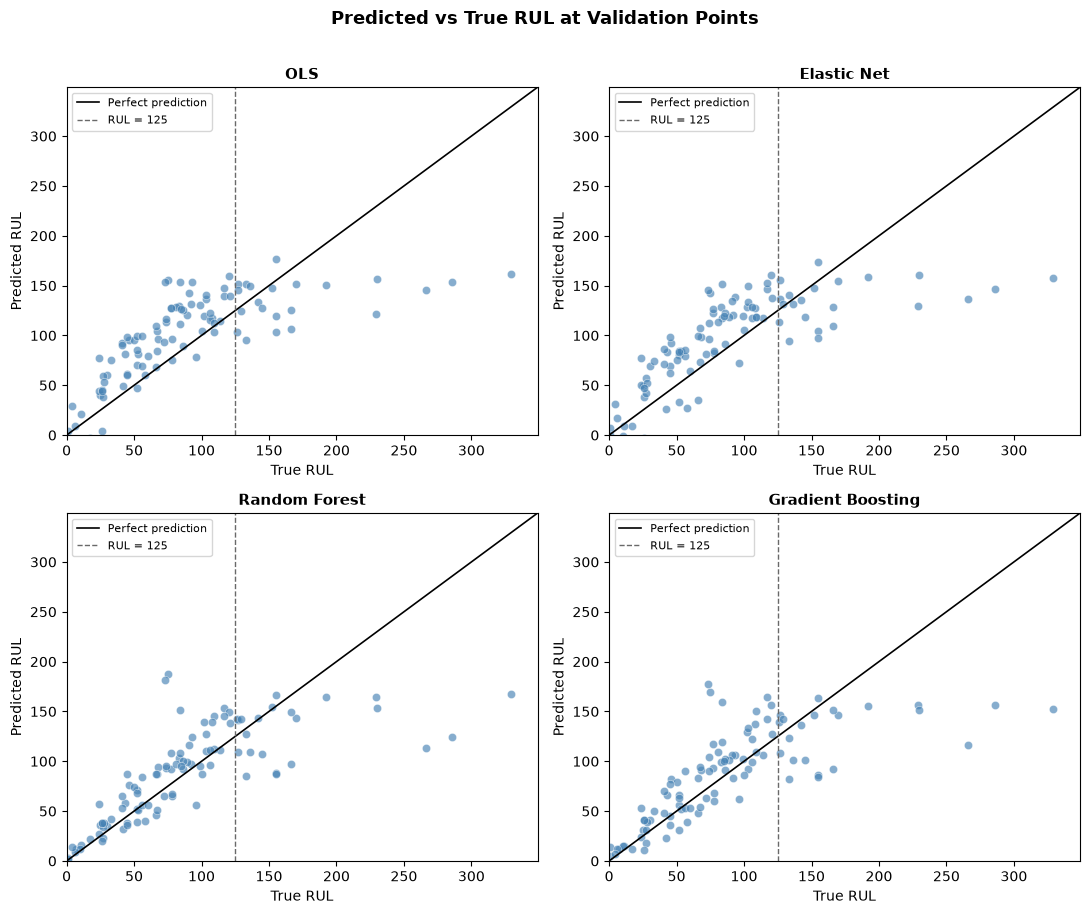

Saved → results/the_gap.png


In [5]:
MODEL_LABELS = {
    "ols_v1":           "OLS",
    "elastic_net_v2":   "Elastic Net",
    "random_forest":    "Random Forest",
    "gradient_boosting": "Gradient Boosting",
}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

x_all = val["rul"].values
axis_max = max(x_all.max(), max(val[m].values.max() for m in MODELS)) + 20

for i, model in enumerate(MODELS):
    ax    = axes[i]
    y_hat = val[model].values

    ax.scatter(x_all, y_hat, alpha=0.65, s=35, color="steelblue", edgecolors="white", linewidths=0.4)
    ax.plot([0, axis_max], [0, axis_max], color="black",  linewidth=1.2, label="Perfect prediction")
    ax.axvline(x=THRESHOLD, color="dimgray", linestyle="--", linewidth=1.0, label="RUL = 125")

    ax.set_xlim(0, axis_max)
    ax.set_ylim(0, axis_max)
    ax.set_xlabel("True RUL",      fontsize=10)
    ax.set_ylabel("Predicted RUL", fontsize=10)
    ax.set_title(MODEL_LABELS[model], fontsize=11, fontweight="bold")
    ax.legend(fontsize=8)

fig.suptitle("Predicted vs True RUL at Validation Points", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("../results/the_gap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → results/the_gap.png")

## 5. Where the models stop

Validation points with true RUL > 200 reveal the prediction ceiling — no model can tell "200 left" from "300 left".

In [6]:
far = val[val["rul"] > 200]

print(f"Validation points with true RUL > 200: {len(far)}")
print(f"Mean true RUL: {far['rul'].mean():.1f}")
print()
print("Mean model prediction for these points:")
for model in MODELS:
    print(f"  {model:22s}: {far[model].mean():.1f}")
print()
print("Largest prediction across all 100 validation points:")
for model in MODELS:
    print(f"  {model:22s}: {val[model].max():.1f}")

Validation points with true RUL > 200: 5
Mean true RUL: 268.0

Mean model prediction for these points:
  ols_v1                : 147.7
  elastic_net_v2        : 146.2
  random_forest         : 144.7
  gradient_boosting     : 146.4

Largest prediction across all 100 validation points:
  ols_v1                : 177.1
  elastic_net_v2        : 173.6
  random_forest         : 187.2
  gradient_boosting     : 177.5


## 6. Findings

- **Best model overall:** Gradient Boosting has the lowest test MAE (18.54) and RMSE (25.33); Random Forest is almost identical (18.95 / 25.88). Both tree models clearly beat the linear baselines (OLS 24.91 / 31.17).
- **Early vs late error:** On the validation set, early RMSE is roughly 65–70 cycles across all models, versus 26–34 cycles for late points — the models are far less reliable when the engine still has a long life ahead.
- **Over-prediction near failure:** 69–88 % of late validation points are over-predicted (model says more life is left than there is). Gradient Boosting is least affected (69 %), OLS worst (88 %). Over-prediction near failure is the costly mistake in a real maintenance setting.
- **Validation vs test:** Test MAE is consistently lower than validation MAE (e.g., Random Forest 18.95 vs 25.03). The 22 early validation points (mean true RUL 268, mean prediction ≈145) dominate the validation squared error; the test cut-offs likely sit closer to failure, so there are fewer extreme-RUL points.
- **The gap:** Every model caps predictions at roughly 175–190 cycles. For the 5 validation points with mean true RUL 268, the mean predictions are only 144–148. Fixed 10-cycle rolling summaries cannot see how long an engine has been degrading — that is the gap Phase 2 (LSTM) is designed to close.